
# **Практическая работа №5. Линейная и логистическая регрессия**



## **Линейная регрессия**



### **Задание №1. Прогнозирование продаж автомобилей**

- **Шаг 1**: Загрузите набор данных о продажах автомобилей, содержащий информацию о цене, возрасте, пробеге и других характеристиках.
  - **Совет №1**: Проверьте данные на наличие пропущенных значений и выбросов. Используйте `pandas` для обнаружения пропусков (`df.isnull().sum()`) и выбросов (например, с помощью метода межквартильного размаха - `df.boxplot()`).
  - **Совет №2**: Для пропущенных значений используйте стратегию заполнения средними значениями или медианой, чтобы минимизировать влияние на распределение данных (`df.fillna()`).




- Ссылка на набор данных: https://www.kaggle.com/datasets/gagandeep16/car-sales

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("Car_sales.csv")

print(df.isnull().sum())

df2 = pd.get_dummies(
    df,
    columns=["Manufacturer", "Latest_Launch", "Model", "Vehicle_type"],
    drop_first=True
)

df2 = df2.fillna(df2.mean(numeric_only=True))

df2.head()

Manufacturer            0
Model                   0
Sales_in_thousands      0
__year_resale_value    36
Vehicle_type            0
Price_in_thousands      2
Engine_size             1
Horsepower              1
Wheelbase               1
Width                   1
Length                  1
Curb_weight             2
Fuel_capacity           1
Fuel_efficiency         3
Latest_Launch           0
Power_perf_factor       2
dtype: int64


,Sales_in_thousands,__year_resale_value,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,...,Model_Town car,Model_V40,Model_V70,Model_Villager,Model_Viper,Model_Voyager,Model_Windstar,Model_Wrangler,Model_Xterra,Vehicle_type_Passenger
0,16.919,16.360,21.500000,1.8,140.0,101.2,67.3,172.4,2.639,13.2,...,False,False,False,False,False,False,False,False,False,True
1,39.384,19.875,28.400000,3.2,225.0,108.1,70.3,192.9,3.517,17.2,...,False,False,False,False,False,False,False,False,False,True
2,14.114,18.225,27.390755,3.2,225.0,106.9,70.6,192.0,3.470,17.2,...,False,False,False,False,False,False,False,False,False,True
3,8.588,29.725,42.000000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,...,False,False,False,False,False,False,False,False,False,True
4,20.397,22.255,23.990000,1.8,150.0,102.6,68.2,178.0,2.998,16.4,...,False,False,False,False,False,False,False,False,False,True


- **Шаг 2**: Проведите предварительный анализ данных:
  - Постройте гистограммы для каждого числового признака, чтобы понять их распределение.
  - Постройте диаграммы рассеяния для выявления зависимостей между признаками и целевой переменной (ценой).
  - **Совет**: Используйте корреляционную матрицу для выявления сильных линейных зависимостей между признаками.

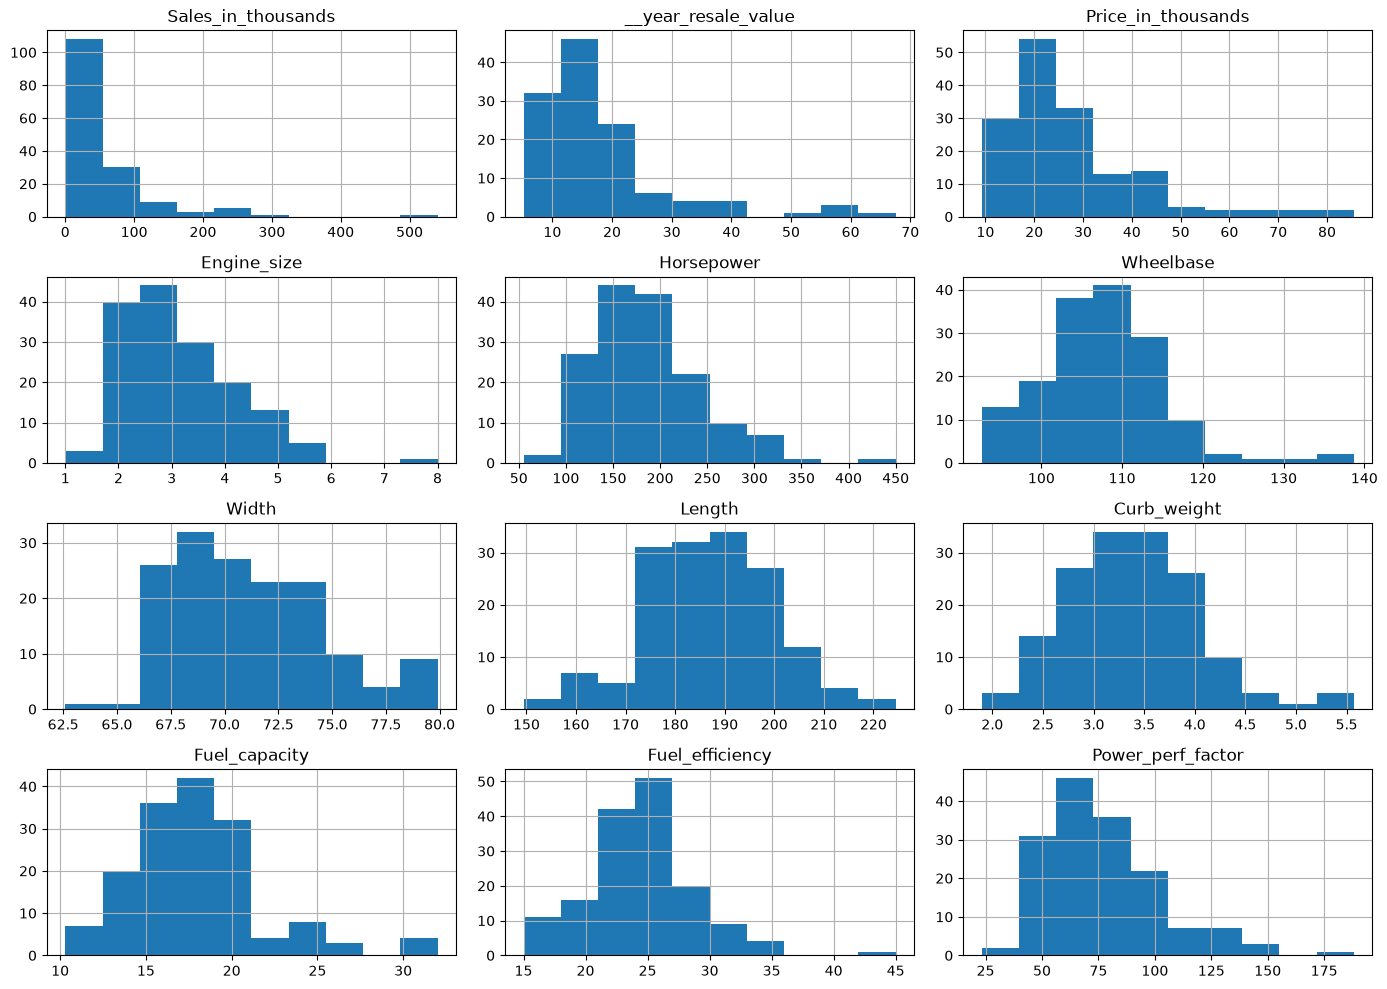

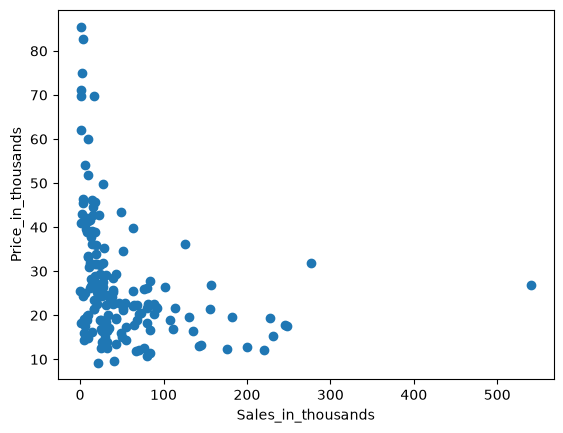

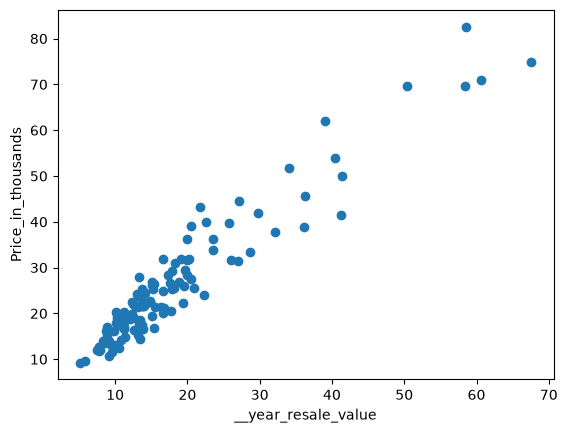

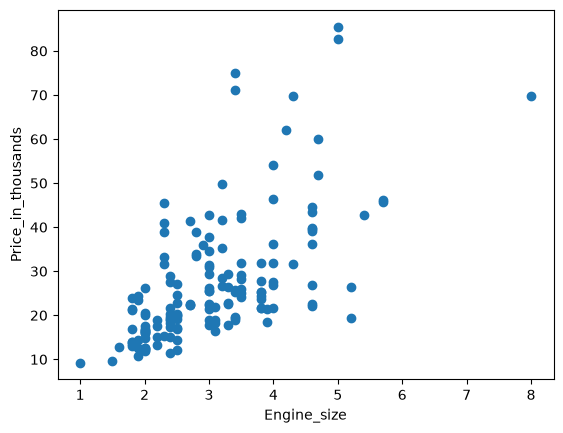

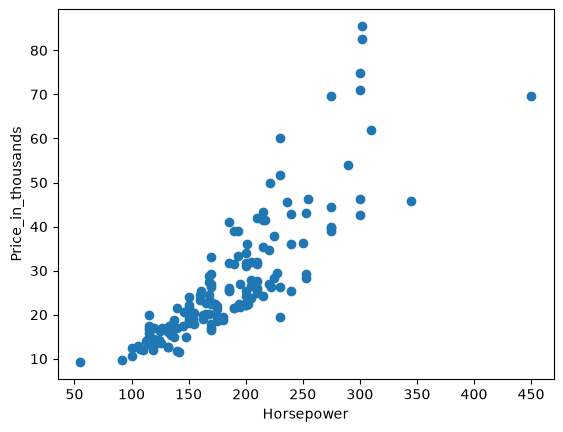

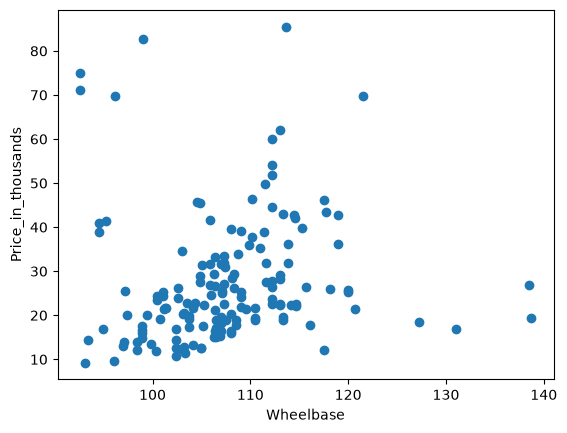

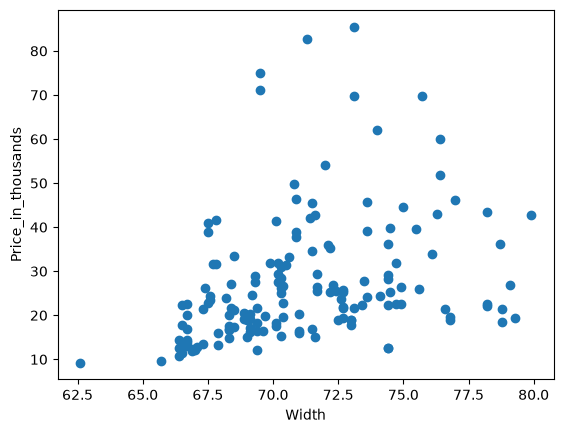

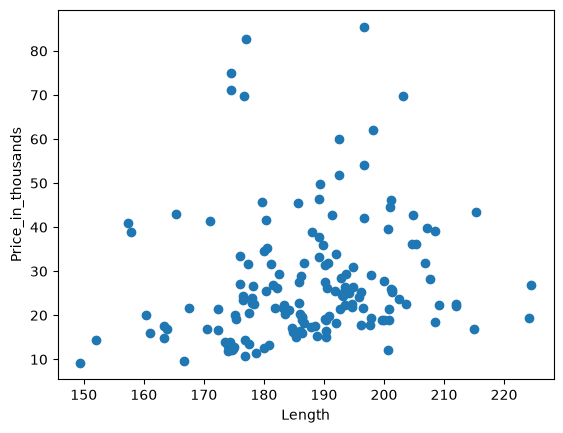

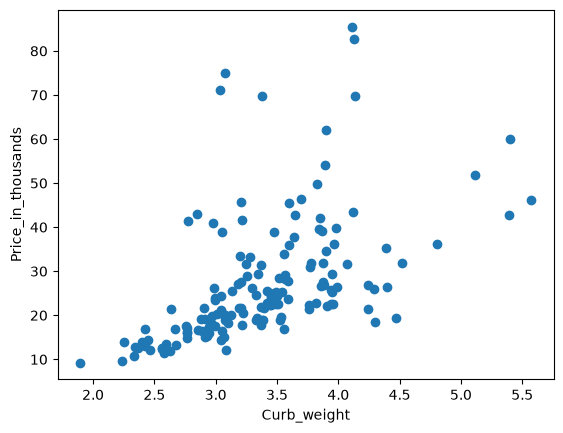

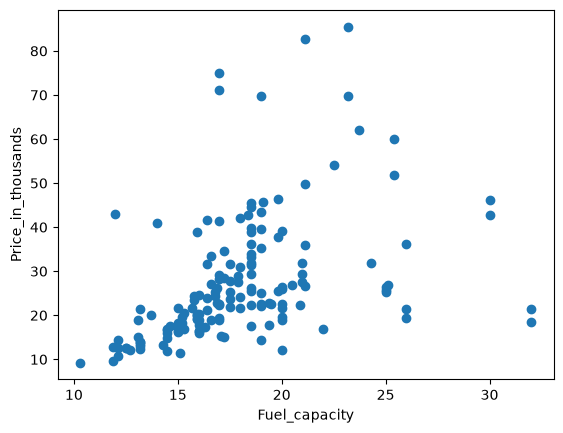

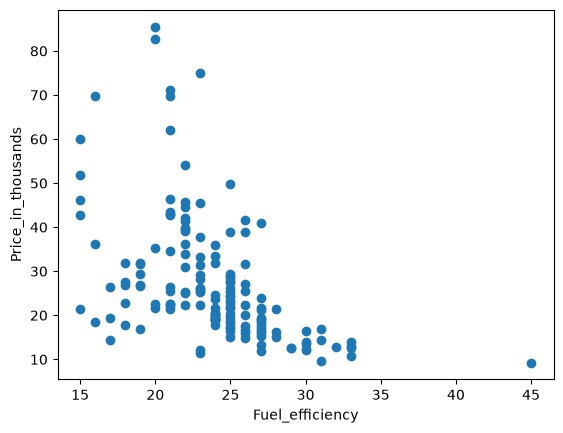

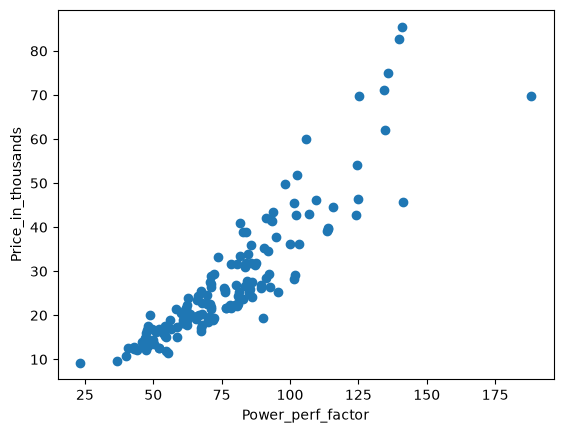

In [6]:
import matplotlib.pyplot as plt

df.select_dtypes(include=np.number).hist(figsize=(14, 10))
plt.tight_layout()
plt.show()

a = df.select_dtypes(include=np.number)

for i in a.columns:
    if i != "Price_in_thousands":
        plt.scatter(a[i], a["Price_in_thousands"])
        plt.xlabel(i)
        plt.ylabel("Price_in_thousands")
        plt.show()

- **Шаг 3**: Разделите данные на обучающую и тестовую выборки (например, 70% на обучение и 30% на тестирование) с помощью `train_test_split` из `sklearn.model_selection`.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df2.drop("Price_in_thousands", axis=1)
y = df2["Price_in_thousands"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(109, 325) (48, 325)


- **Шаг 4**: Постройте и обучите модели линейной регрессии с различными типами регуляризации:
  - Обучите базовую модель `LinearRegression` (без регуляризации).
  - Обучите модель **Ridge** (L2-регуляризация) с подбором гиперпараметра `alpha` с помощью `GridSearchCV`.
  - Обучите модель **Lasso** (L1-регуляризация) с подбором гиперпараметра `alpha` с помощью `RandomizedSearchCV`.
  - Обучите модель **ElasticNet** (комбинация L1 и L2) с подбором гиперпараметров `alpha` и `l1_ratio` с помощью `GridSearchCV` и/или `RandomizedSearchCV`.
  - **Совет**: Используйте `np.logspace(-4, 4, 50)` для генерации сетки значений `alpha`.



In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV
import numpy as np

a = LinearRegression()

b = GridSearchCV(
    Ridge(),
    {"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    n_jobs=-1
)
b.fit(X_train_scaled, y_train)

c = GridSearchCV(
    Lasso(max_iter=50000),
    {"alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    n_jobs=-1
)
c.fit(X_train_scaled, y_train)

d = GridSearchCV(
    ElasticNet(max_iter=50000),
    {
        "alpha": [0.001, 0.01, 0.1, 1],
        "l1_ratio": [0.2, 0.5, 0.8]
    },
    cv=5,
    n_jobs=-1
)
d.fit(X_train_scaled, y_train)

models = {
    "Linear Regression": a,
    "Ridge": b.best_estimator_,
    "Lasso": c.best_estimator_,
    "ElasticNet": d.best_estimator_
}

print("Ridge:", b.best_params_)
print("Lasso:", c.best_params_)
print("ElasticNet:", d.best_params_)

Ridge: {'alpha': 0.01}
Lasso: {'alpha': 1}
ElasticNet: {'alpha': 1, 'l1_ratio': 0.8}


- **Шаг 5**: Оцените качество всех моделей с использованием метрик MSE, RMSE, MAE и R².
  - Выведите значения метрик для каждой модели и интерпретируйте их.


In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results[name] = {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    predictions[name] = pred

    print(name)
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))
    print("R2:", round(r2, 4))
    print()

Linear Regression
MSE: 22.9916
RMSE: 4.795
MAE: 3.345
R2: 0.8598

Ridge
MSE: 22.9923
RMSE: 4.795
MAE: 3.345
R2: 0.8598

Lasso
MSE: 17.041
RMSE: 4.1281
MAE: 2.9489
R2: 0.8961

ElasticNet
MSE: 16.8284
RMSE: 4.1022
MAE: 3.0627
R2: 0.8974



- **Шаг 6**: Визуализируйте результаты:
  - Постройте график зависимости предсказанных цен от фактических для каждой модели.



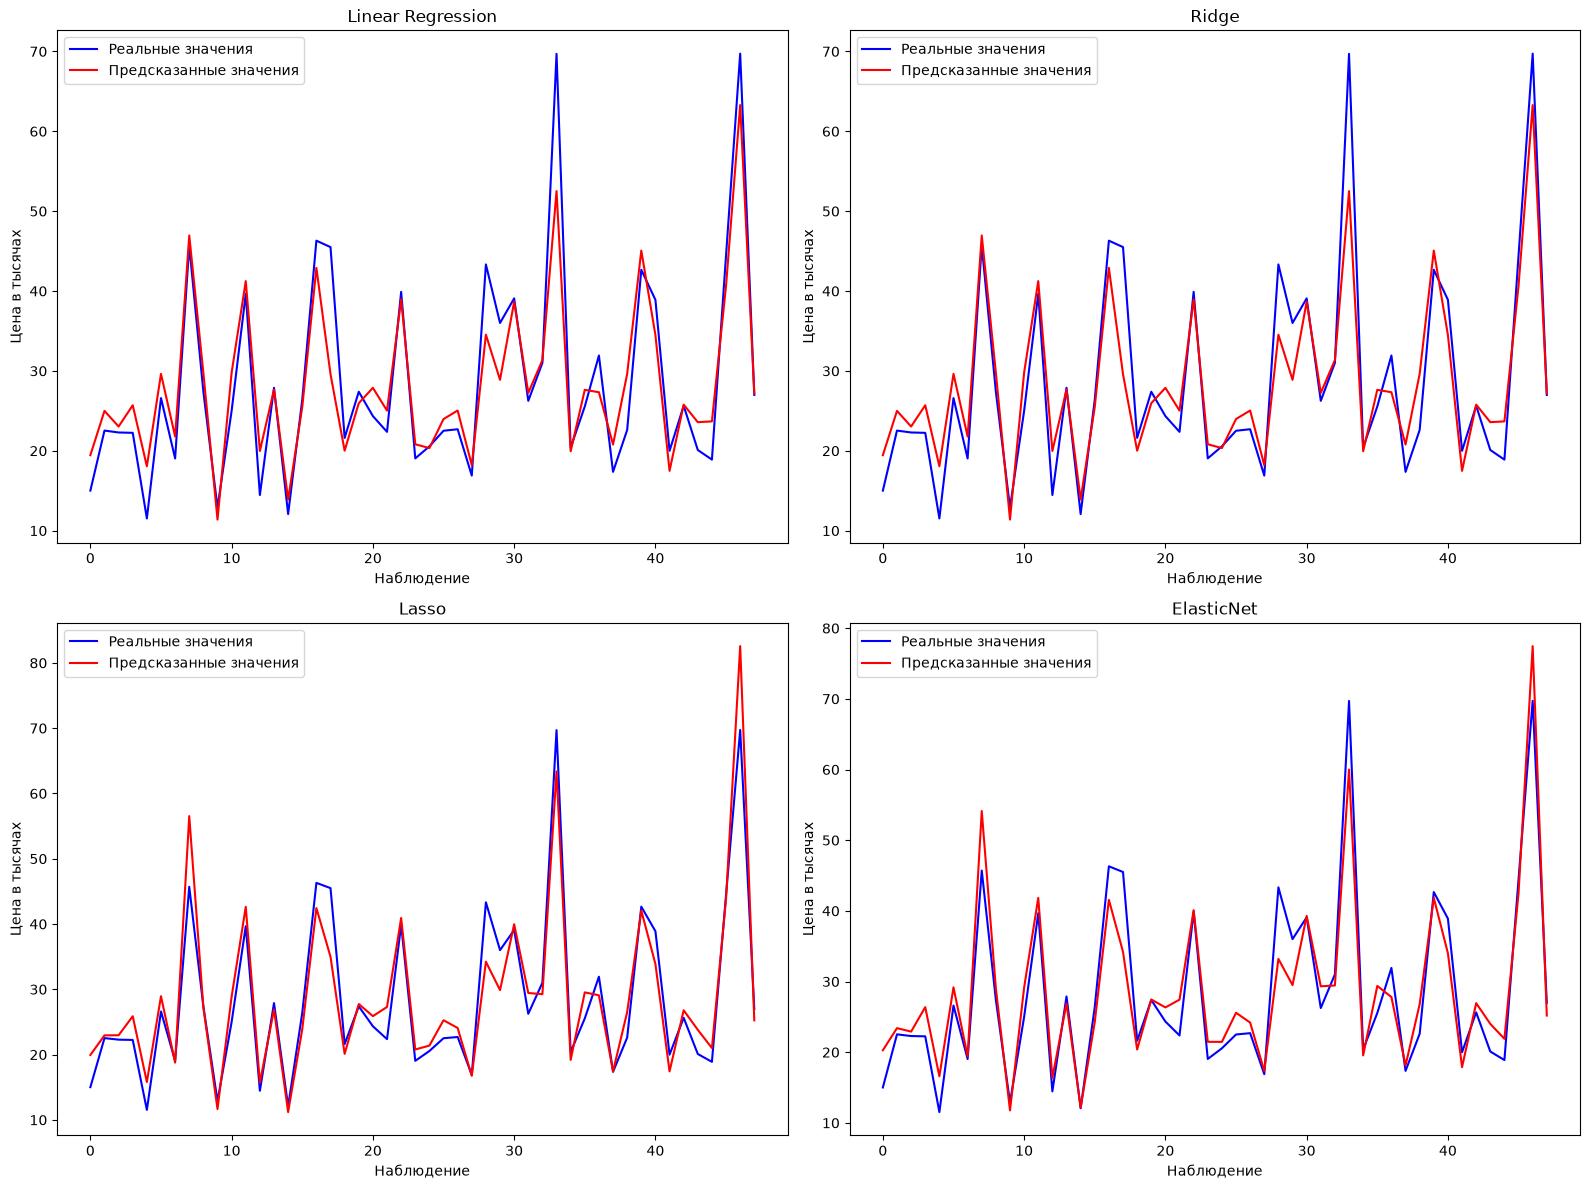

In [10]:
real = y_test.values

plt.figure(figsize=(16, 12))

for i, name in enumerate(predictions):
    plt.subplot(2, 2, i + 1)
    plt.plot(real, label="Реальные значения", color="blue")
    plt.plot(predictions[name], label="Предсказанные значения", color="red")
    plt.title(name)
    plt.xlabel("Наблюдение")
    plt.ylabel("Цена в тысячах")
    plt.legend()

plt.tight_layout()
plt.show()



- **Шаг 7**: **Сравните все модели между собой по целевым метрикам (MSE, RMSE, MAE, R²)**:
  - Создайте сводную таблицу с метриками для всех моделей.
  - Определите лучшую модель и выведите для неё все метрики, а также оптимальные гиперпараметры.


In [11]:
result = pd.DataFrame.from_dict(results, orient="index")
result = result.sort_values("R2", ascending=False)

display(result)

best_name = result.index[0]
best_model = models[best_name]

print("Лучшая модель:", best_name)
print("Гиперпараметры:", best_model)

,MSE,RMSE,MAE,R2
ElasticNet,16.828433,4.102247,3.062737,0.897417
Lasso,17.041029,4.128078,2.948936,0.896122
Linear Regression,22.991595,4.794955,3.345001,0.859848
Ridge,22.992336,4.795032,3.345045,0.859844


Лучшая модель: ElasticNet
Гиперпараметры: ElasticNet(alpha=1, l1_ratio=0.8, max_iter=50000)


---



### **Задание №2. Влияние погодных условий на урожайность**




- **Шаг 1**: Загрузите набор данных о погодных условиях и урожайности сельскохозяйственных культур.
  - **Совет**: Проверьте данные на наличие пропущенных значений и выбросов. Используйте стратегию заполнения пропусков средними значениями или медианой.

- Ссылка на набор данных: https://www.kaggle.com/datasets/waqi786/climate-change-impact-on-agriculture


Year                           0
Country                        0
Region                         0
Crop_Type                      0
Average_Temperature_C          0
Total_Precipitation_mm         0
CO2_Emissions_MT               0
Crop_Yield_MT_per_HA           0
Extreme_Weather_Events         0
Irrigation_Access_%            0
Pesticide_Use_KG_per_HA        0
Fertilizer_Use_KG_per_HA       0
Soil_Health_Index              0
Adaptation_Strategies          0
Economic_Impact_Million_USD    0
dtype: int64


,Year,Country,Region,Crop_Type,Average_Temperature_C,Total_Precipitation_mm,CO2_Emissions_MT,Crop_Yield_MT_per_HA,Extreme_Weather_Events,Irrigation_Access_%,Pesticide_Use_KG_per_HA,Fertilizer_Use_KG_per_HA,Soil_Health_Index,Adaptation_Strategies,Economic_Impact_Million_USD
0,2001,India,West Bengal,Corn,1.55,447.06,15.22,1.737,8,14.54,10.08,14.78,83.25,Water Management,808.13
1,2024,China,North,Corn,3.23,2913.57,29.82,1.737,8,11.05,33.06,23.25,54.02,Crop Rotation,616.22
2,2001,France,Ile-de-France,Wheat,21.11,1301.74,25.75,1.719,5,84.42,27.41,65.53,67.78,Water Management,796.96
3,2001,Canada,Prairies,Coffee,27.85,1154.36,13.91,3.890,5,94.06,14.38,87.58,91.39,No Adaptation,790.32
4,1998,India,Tamil Nadu,Sugarcane,2.19,1627.48,11.81,1.080,9,95.75,44.35,88.08,49.61,Crop Rotation,401.72


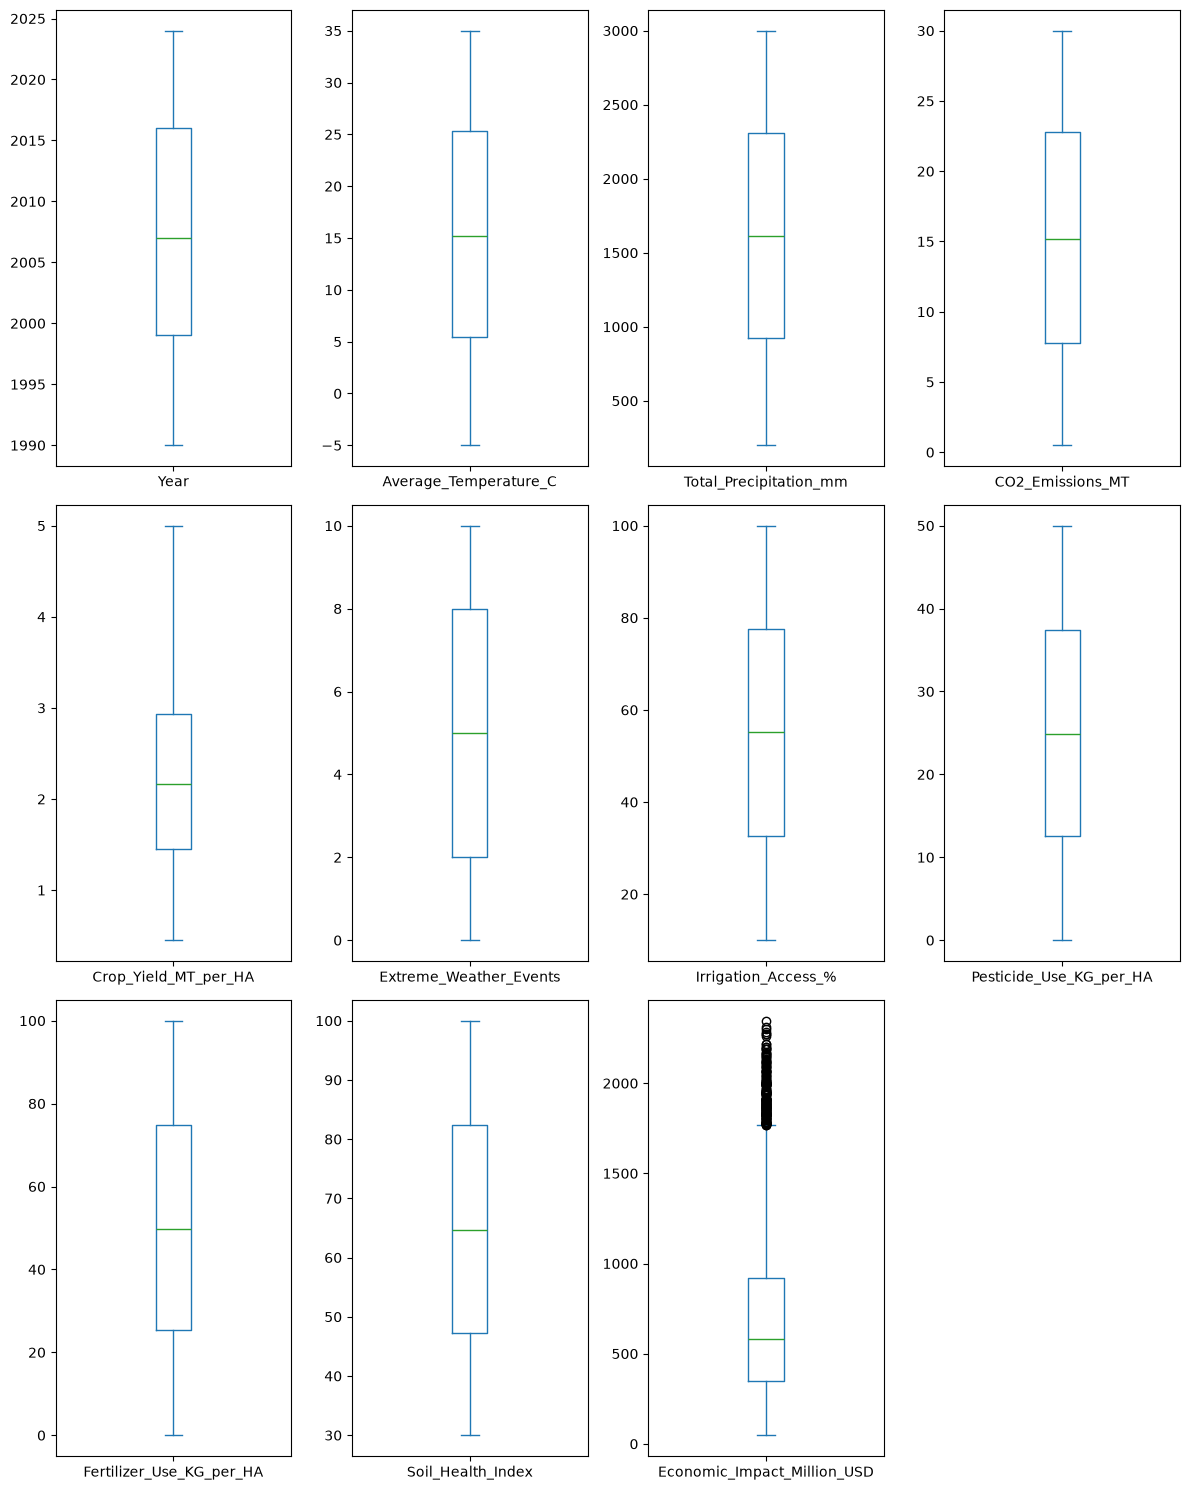

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("climate_change.csv")

print(df.isnull().sum())
display(df.head())

df.plot(kind="box", subplots=True, layout=(3, 4), figsize=(12, 15))
plt.tight_layout()
plt.show()




- **Шаг 2**: Выполните анализ данных:
  - Постройте корреляционную матрицу для выявления зависимостей между признаками.
  - Постройте диаграммы рассеяния для ключевых признаков.
  - **Совет**: Удалите или преобразуйте признаки с низкой корреляцией с целевой переменной, чтобы улучшить модель.



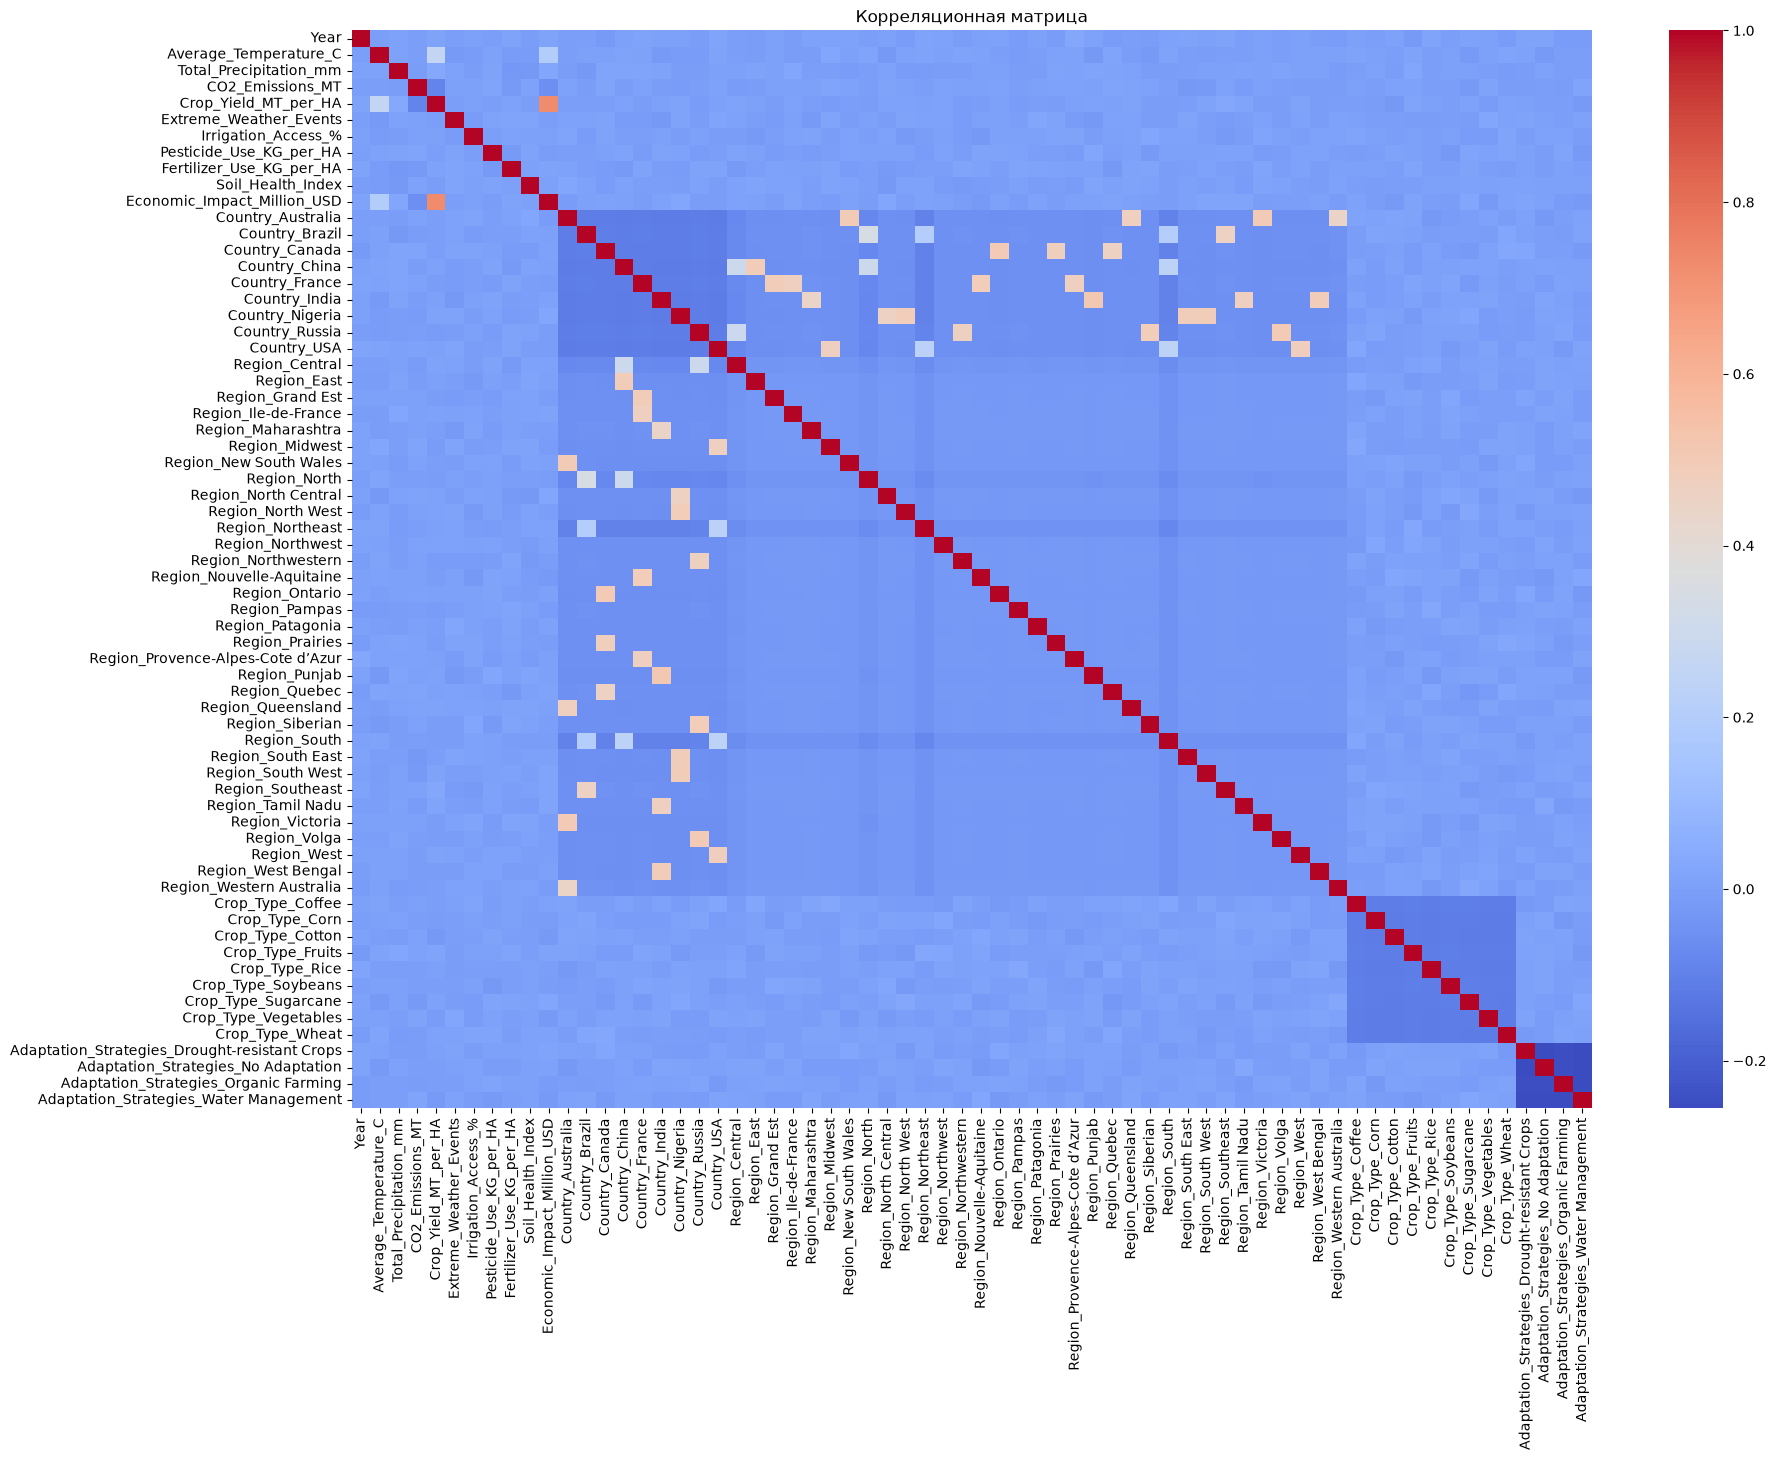

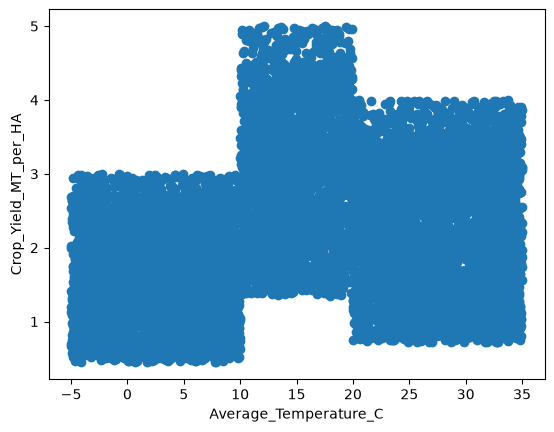

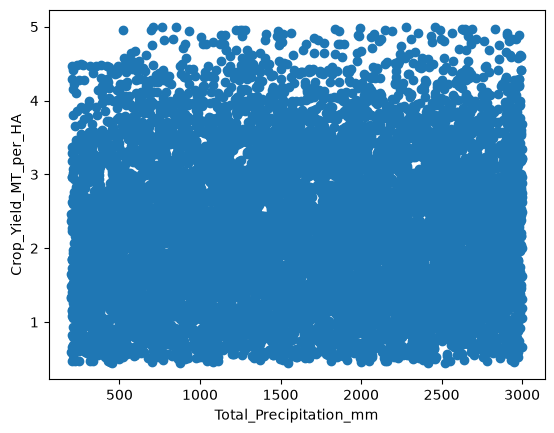

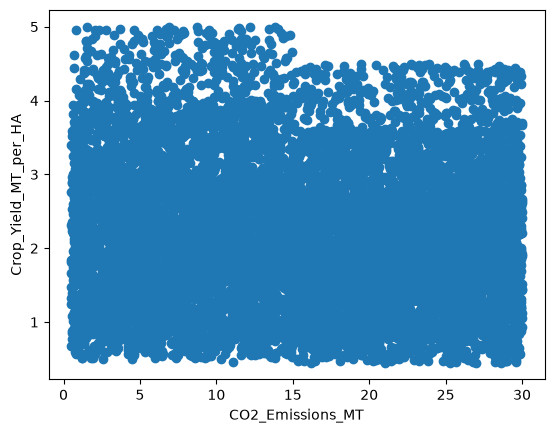

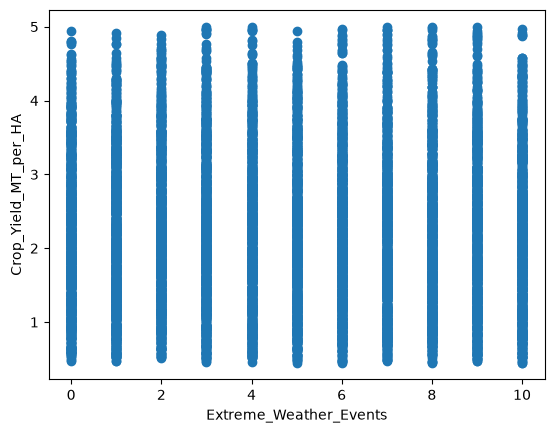

In [13]:
import seaborn as sns

df2 = pd.get_dummies(
    df,
    columns=["Country", "Region", "Crop_Type", "Adaptation_Strategies"],
    drop_first=True
)

plt.figure(figsize=(20, 14))
sns.heatmap(df2.corr(), cmap="coolwarm")
plt.title("Корреляционная матрица")
plt.show()

df3 = df.drop(
    ["Irrigation_Access_%", "Crop_Type", "Adaptation_Strategies", "Country", "Region"],
    axis=1
)

a = [
    "Average_Temperature_C",
    "Total_Precipitation_mm",
    "CO2_Emissions_MT",
    "Extreme_Weather_Events"
]

for i in a:
    plt.scatter(df3[i], df3["Crop_Yield_MT_per_HA"])
    plt.xlabel(i)
    plt.ylabel("Crop_Yield_MT_per_HA")
    plt.show()

- **Шаг 3**: Разделите данные на обучающую и тестовую выборки.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df4 = df3.drop(
    [
        "Year",
        "Pesticide_Use_KG_per_HA",
        "Fertilizer_Use_KG_per_HA",
        "Soil_Health_Index",
        "Economic_Impact_Million_USD"
    ],
    axis=1
)

X = df4.drop("Crop_Yield_MT_per_HA", axis=1)
y = df4["Crop_Yield_MT_per_HA"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
X_train.head()

(7000, 4) (3000, 4)


,Average_Temperature_C,Total_Precipitation_mm,CO2_Emissions_MT,Extreme_Weather_Events
4083,1.51,929.08,14.45,0
1996,30.62,208.20,9.69,5
6607,33.04,364.49,20.05,7
3322,24.55,1728.43,26.42,7
7057,10.67,2073.40,6.05,5




- **Шаг 4**: Постройте и обучите модели линейной регрессии с различными типами регуляризации для оценки влияния температуры и уровня осадков на урожайность:
  - Обучите базовую модель `LinearRegression` (без регуляризации).
  - Обучите модель **Ridge** (L2-регуляризация) с подбором гиперпараметра `alpha` с помощью `RandomizedSearchCV`.
  - Обучите модель **Lasso** (L1-регуляризация) с подбором гиперпараметра `alpha` с помощью `GridSearchCV`.
  - Обучите модель **ElasticNet** с подбором гиперпараметров `alpha` и `l1_ratio` с помощью `GridSearchCV` и/или `RandomizedSearchCV` .

In [15]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

a = LinearRegression()

b = GridSearchCV(
    Ridge(),
    {"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    n_jobs=-1
)
b.fit(X_train_scaled, y_train)

c = GridSearchCV(
    Lasso(max_iter=50000),
    {"alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    n_jobs=-1
)
c.fit(X_train_scaled, y_train)

d = GridSearchCV(
    ElasticNet(max_iter=50000),
    {
        "alpha": [0.001, 0.01, 0.1, 1],
        "l1_ratio": [0.2, 0.5, 0.8]
    },
    cv=5,
    n_jobs=-1
)
d.fit(X_train_scaled, y_train)

models = {
    "Linear Regression": a,
    "Ridge": b.best_estimator_,
    "Lasso": c.best_estimator_,
    "ElasticNet": d.best_estimator_
}

print("Ridge:", b.best_params_)
print("Lasso:", c.best_params_)
print("ElasticNet:", d.best_params_)

Ridge: {'alpha': 100}
Lasso: {'alpha': 0.001}
ElasticNet: {'alpha': 0.001, 'l1_ratio': 0.2}


- **Шаг 5**: Проведите оценку точности всех моделей.
  - Выведите значения метрик MSE, RMSE, MAE и R² для каждой модели и интерпретируйте их.

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results[name] = {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    predictions[name] = pred

    print(name)
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))
    print("R2:", round(r2, 4))
    print()

Linear Regression
MSE: 0.9053
RMSE: 0.9515
MAE: 0.7797
R2: 0.075

Ridge
MSE: 0.9052
RMSE: 0.9514
MAE: 0.7799
R2: 0.0751

Lasso
MSE: 0.9052
RMSE: 0.9514
MAE: 0.7797
R2: 0.0751

ElasticNet
MSE: 0.9052
RMSE: 0.9514
MAE: 0.7797
R2: 0.075





- **Шаг 6**: Визуализируйте данные и результаты моделей:
  - Постройте графики зависимости предсказанных значений от фактических для каждой модели.

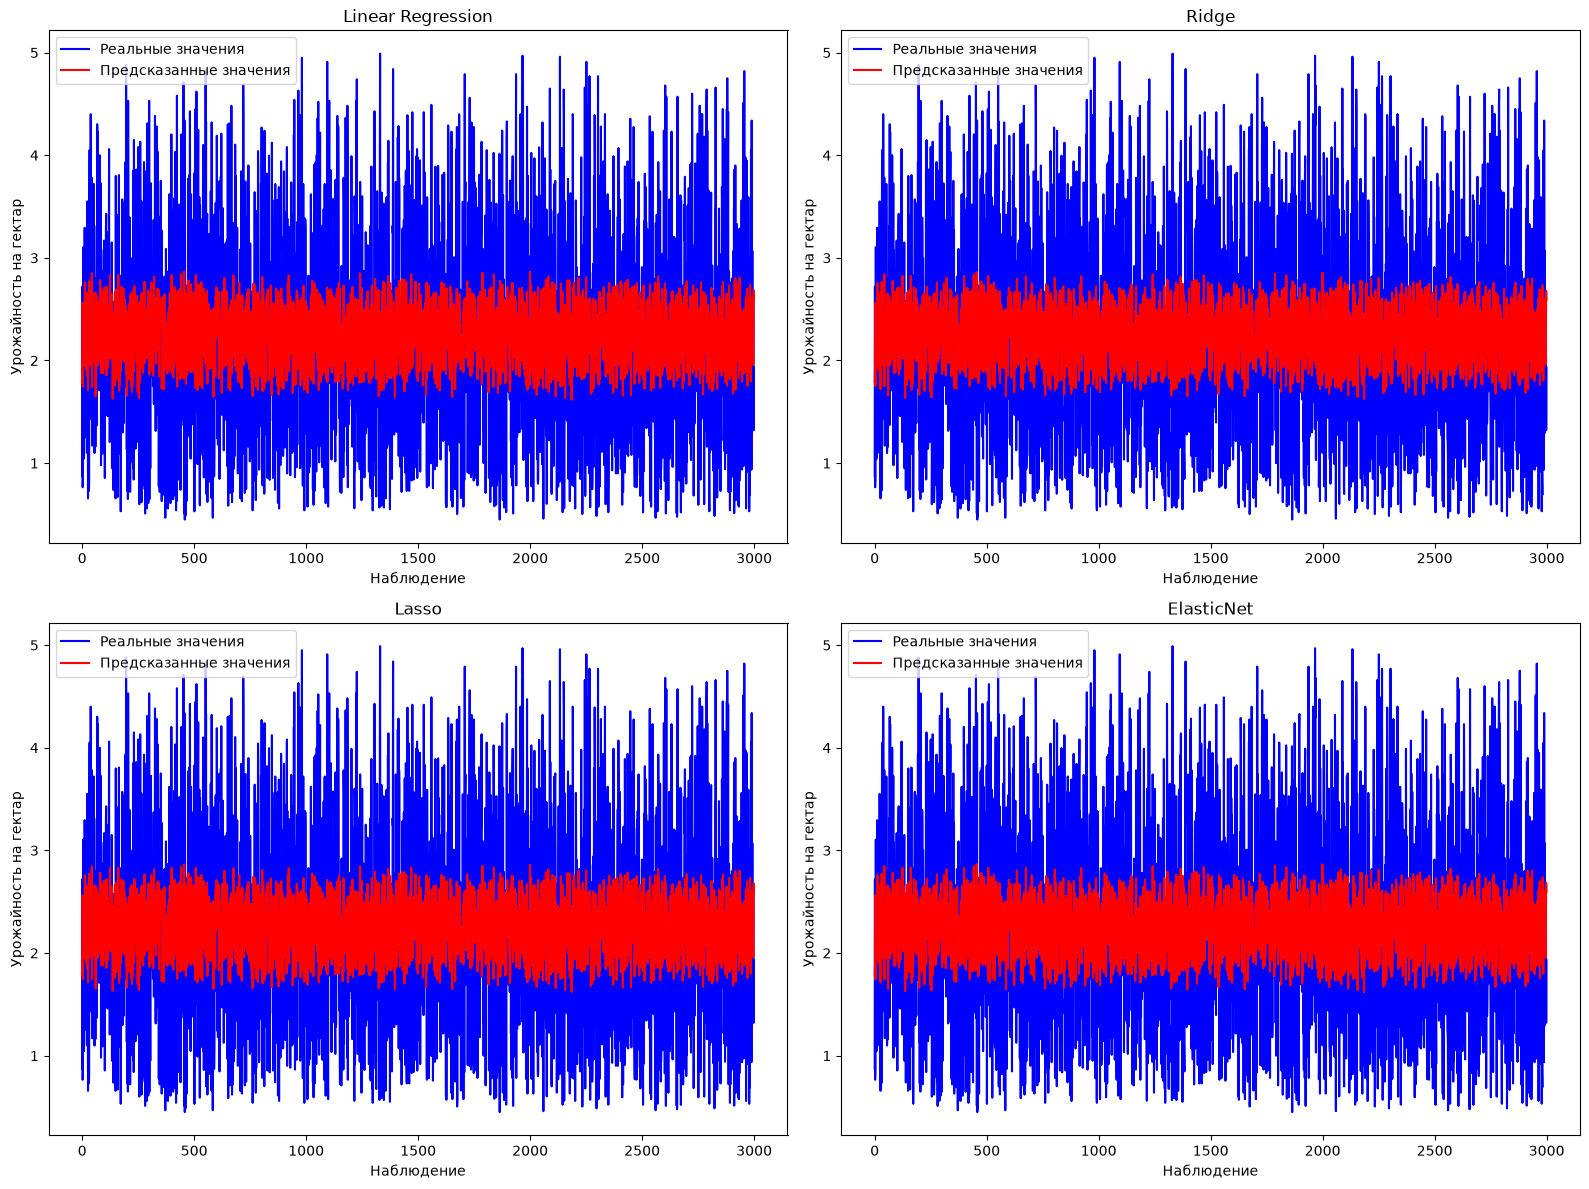

In [17]:
real = y_test.values

plt.figure(figsize=(16, 12))

for i, name in enumerate(predictions):
    plt.subplot(2, 2, i + 1)
    plt.plot(real, label="Реальные значения", color="blue")
    plt.plot(predictions[name], label="Предсказанные значения", color="red")
    plt.title(name)
    plt.xlabel("Наблюдение")
    plt.ylabel("Урожайность на гектар")
    plt.legend()

plt.tight_layout()
plt.show()

- **Шаг 7**: **Сравните все модели между собой по целевым метрикам (MSE, RMSE, MAE, R²)**:
  - Создайте сводную таблицу с метриками для всех моделей.
  - Определите лучшую модель и выведите для неё все метрики, а также оптимальные гиперпараметры.

In [18]:
result = pd.DataFrame.from_dict(results, orient="index")
result = result.sort_values("R2", ascending=False)

display(result)

best_name = result.index[0]
best_model = models[best_name]

print("Лучшая модель:", best_name)
print("Гиперпараметры:", best_model)

,MSE,RMSE,MAE,R2
Ridge,0.905189,0.951414,0.779859,0.075106
Lasso,0.905198,0.951419,0.779741,0.075097
ElasticNet,0.905245,0.951443,0.779747,0.075049
Linear Regression,0.905263,0.951453,0.779740,0.075030


Лучшая модель: Ridge
Гиперпараметры: Ridge(alpha=100)


- **Шаг 8: Проанализируйте влияние признаков на урожайность**

  - На основе лучшей модели проведите анализ важности признаков:

    - Извлеките коэффициенты (`coef_`) лучшей модели и сопоставьте их с названиями признаков.
    - Визуализируйте важность признаков с помощью горизонтальной столбчатой диаграммы.
    - Проинтерпретируйте результаты: определите, какие погодные факторы (температура, осадки, CO₂ и др.) оказывают наибольшее положительное и отрицательное влияние на урожайность.
    - **Совет**: Для модели Lasso обратите внимание на признаки с нулевыми коэффициентами — они были исключены как незначимые.
    - **Совет**: Если данные были стандартизированы (`StandardScaler`), коэффициенты можно напрямую сравнивать по абсолютной величине для оценки относительной важности.



                  Признак  Коэффициент
0   Average_Temperature_C     0.260825
1  Total_Precipitation_mm     0.020654
2        CO2_Emissions_MT    -0.091037
3  Extreme_Weather_Events    -0.011222


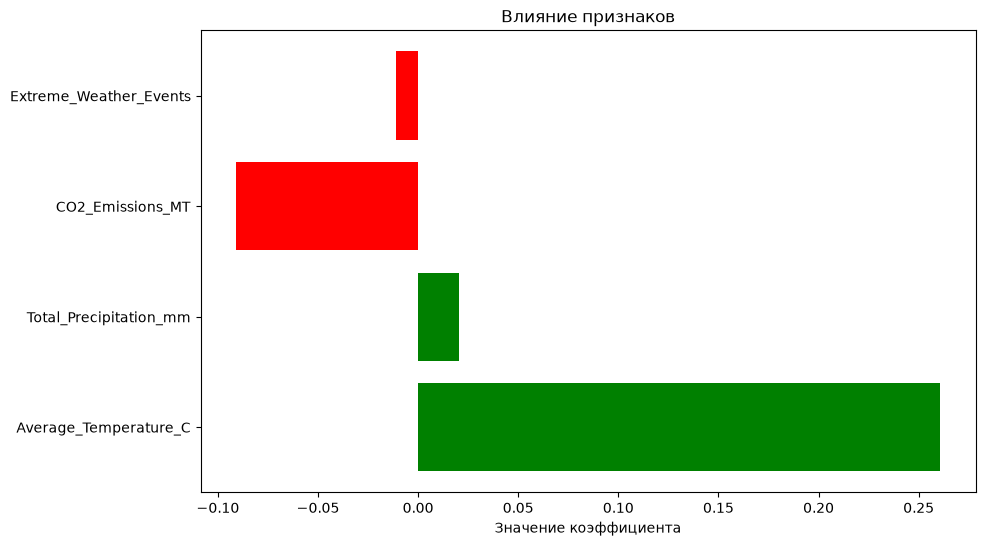

In [19]:
a = pd.DataFrame({
    "Признак": X.columns,
    "Коэффициент": best_model.coef_
})

print(a)

plt.figure(figsize=(10, 6))

colors = ["green" if i > 0 else "red" for i in a["Коэффициент"]]

plt.barh(a["Признак"], a["Коэффициент"], color=colors)
plt.xlabel("Значение коэффициента")
plt.title("Влияние признаков")
plt.show()

#### **Интерпретация результатов (пример формулировки для отчёта):**


**Интерпретация:** положительный коэффициент означает положительное влияние признака на урожайность, отрицательный — отрицательное. После запуска предыдущей ячейки конкретные признаки и их коэффициенты будут выведены в таблице.


> На основе анализа коэффициентов лучшей модели установлено, что:
> - **Положительное влияние** на урожайность оказывают: [перечислить признаки с положительными коэффициентами].
> - **Отрицательное влияние** на урожайность оказывают: [перечислить признаки с отрицательными коэффициентами].
> - Наиболее значимым фактором является [название признака] с коэффициентом [значение], что означает: при увеличении данного показателя на 1 единицу (при прочих равных) урожайность изменяется на [значение коэффициента] единиц.

---



## **Логистическая регрессия**



### **Задание №3. Классификация клиентов банка**

- **Шаг 1**: Загрузите набор данных о клиентах банка, включающий данные о возрасте, доходе, кредитной истории и других характеристиках.
  - **Совет**: Проверьте данные на наличие пропущенных значений и выбросов. Используйте стратегию заполнения пропусков средними значениями или медианой.



- Ссылка на набор данных: https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing/data

In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv("bank-additional-full.csv", sep=";")

y = df["y"]
df = df.drop("y", axis=1)

print(df.isnull().sum())
display(df.head())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0


- **Шаг 2**: Проведите анализ данных и предобработку:
  - Закодируйте категориальные переменные с помощью `OneHotEncoder` или `pd.get_dummies`.
  - Нормализуйте числовые признаки с помощью `StandardScaler` для улучшения обучения модели.
  - **Совет**: Убедитесь, что все признаки имеют одинаковый масштаб, чтобы избежать доминирования одного признака над другими.

In [21]:
df2 = pd.get_dummies(
    df,
    columns=[
        "job", "marital", "education", "default", "housing",
        "loan", "contact", "month", "day_of_week", "poutcome"
    ],
    drop_first=True
)

df2.head()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False


- **Шаг 3**: Разделите данные на обучающую и тестовую выборки.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y = y.map({"no": 0, "yes": 1})
X = df2.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3
)

scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

print(X_train.shape, X_test.shape)

(28831, 53) (12357, 53)


- **Шаг 4**: Постройте и обучите модели логистической регрессии с различными типами регуляризации для предсказания вероятности открытия депозитного счета клиентом:
  - Обучите модель `LogisticRegression` с **L2-регуляризацией** (`penalty='l2'`) и подбором гиперпараметра `C` с помощью `GridSearchCV`.
  - Обучите модель `LogisticRegression` с **L1-регуляризацией** (`penalty='l1'`, `solver='saga'`) и подбором гиперпараметра `C` с помощью `RandomizedSearchCV`.
  - Обучите модель `LogisticRegression` с **ElasticNet-регуляризацией** (`penalty='elasticnet'`, `solver='saga'`) и подбором гиперпараметров `C` и `l1_ratio` с помощью `GridSearchCV` и/или `RandomizedSearchCV` .
  - **Совет**: Для L1 и ElasticNet используйте `solver='saga'`, так как он поддерживает оба типа регуляризации.


In [28]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
import numpy as np

# Ваш код
# время выполнения - ~8-9 мин.
model_l2 = LogisticRegression(penalty='l2')
model_l1 = LogisticRegression(penalty='l1', solver='saga')
elnet = LogisticRegression(penalty='elasticnet', solver='saga')

c_arr = np.linspace(0.001, 2, 10) # боялся что они могли замедлять работу, пока были в слова, поэтому перенес отдельно
l1_arr = np.linspace(0.001, 0.99, 20)
# Параметры L1/L2
param_dist = {'C': c_arr}
# Параметры ElasticNet
param_dist_elnet = {'C': c_arr, 'l1_ratio': l1_arr}

gsearch_l2 = GridSearchCV(model_l2, param_dist, cv=5, n_jobs=-1)
gsearch_l2.fit(X, y)
print('done l2') # проверка, что хотя бы прогресс идет
rsearch_l1 = RandomizedSearchCV(model_l1, param_dist, cv=5, n_jobs=-1,
                                random_state=42, n_iter=10)
rsearch_l1.fit(X, y)
print('done l1')
gsearch_elnet = RandomizedSearchCV(elnet, param_dist_elnet, cv=5, n_jobs=-1, n_iter=10)
gsearch_elnet.fit(X, y)
print('done elnet')
models = {
    'Logistic Regression (L2)': gsearch_l2.best_estimator_,
    'Logistic Regression (L1)': rsearch_l1.best_estimator_,
    'ElasticNet (L1 + L2)': gsearch_elnet.best_estimator_
}
print('done')

C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html

done l2


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


done l1


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


done elnet
done


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



- **Шаг 5**: Оцените качество всех моделей с использованием метрик точности (Accuracy), полноты (Recall), точности (Precision) и F1-меры.
  - Выведите значения метрик для каждой модели и интерпретируйте их. Обратите внимание на баланс между точностью и полнотой.
  - Постройте матрицу ошибок для каждой модели с помощью `confusion_matrix` и визуализируйте их с помощью `seaborn.heatmap`.

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {}
predictions = {}
pred_proba = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

    predictions[name] = pred
    pred_proba[name] = prob

    print(name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1:", round(f1, 4))
    print()

C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_mo

Logistic Regression (L2)
Accuracy: 0.9059
Precision: 0.6922
Recall: 0.3144
F1: 0.4324

Logistic Regression (L1)
Accuracy: 0.8985
Precision: 0.7233
Recall: 0.1781
F1: 0.2859



C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


ElasticNet (L1 + L2)
Accuracy: 0.9086
Precision: 0.6605
Recall: 0.4074
F1: 0.504



C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


- **Шаг 6**: Визуализируйте ROC-кривые для всех моделей и вычислите AUC для оценки.
  - Используйте `roc_curve` и `auc` из `sklearn.metrics` для построения и расчёта.
  - Постройте все ROC-кривые на одном графике для наглядного сравнения.



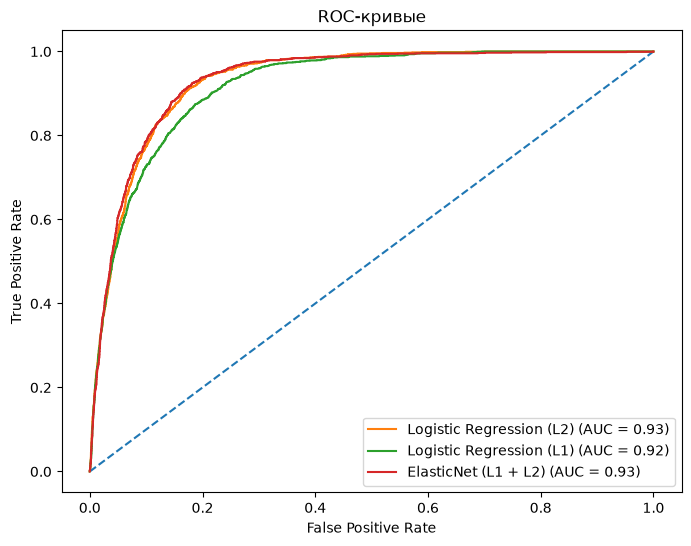

In [30]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], "--")

auc_values = {}

for name in pred_proba:
    fpr, tpr, _ = roc_curve(y_test, pred_proba[name])
    score = auc(fpr, tpr)

    auc_values[name] = score

    plt.plot(fpr, tpr, label=f"{name} (AUC = {score:.2f})")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые")
plt.legend()
plt.show()

- **Шаг 7**: **Сравните все модели между собой по целевым метрикам (Accuracy, Precision, Recall, F1, AUC)**:
  - Создайте сводную таблицу с метриками для всех моделей.
  - Определите лучшую модель и выведите для неё все метрики, оптимальные гиперпараметры и матрицу ошибок.

In [31]:
result = pd.DataFrame.from_dict(results, orient="index")
result["AUC"] = [auc_values[i] for i in result.index]
result = result.sort_values("F1", ascending=False)

display(result)

best_name = result.index[0]
best_model = models[best_name]

print("Лучшая модель:", best_name)
print("Гиперпараметры:", best_model)

,Accuracy,Precision,Recall,F1,AUC
ElasticNet (L1 + L2),0.908554,0.660529,0.407381,0.503951,0.932461
Logistic Regression (L2),0.905883,0.692187,0.314407,0.432406,0.931123
Logistic Regression (L1),0.898519,0.723343,0.178141,0.285877,0.918639


Лучшая модель: ElasticNet (L1 + L2)
Гиперпараметры: LogisticRegression(C=np.float64(0.6673333333333333),
                   l1_ratio=np.float64(0.7817894736842106),
                   penalty='elasticnet', solver='saga')
